# Librerias

In [2]:
import io
import os
import cv2
import time
import numpy as np
import pickle
import subprocess
import re
import shutil
import glob
import matplotlib
import matplotlib.pyplot as plt
import plotly
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.subplots import make_subplots
from ultralytics import YOLOE
import torch

pio.renderers.default = "notebook_connected"

# Configuramos la ruta para que use las fuentes recién instaladas
os.environ["QT_QPA_FONTDIR"] = "/usr/share/fonts/truetype/dejavu/"

%matplotlib inline

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


# Funciones auxiliares

In [3]:
def bounding_box_midpoints(coords_list):
    us=np.zeros((len(coords_list),2))
    for i,coords in enumerate(coords_list):
        # Coordenadas bounding box
        xmin,ymin,xmax,ymax=coords
        # Punto medio
        u=np.array([(xmin + xmax) / 2, (ymin + ymax) / 2])
        us[i]=u
    return us

# Clases auxiliares

In [4]:
class PinholeCameraModel():
    def __init__(self):
        pass

    # Dado el modelo ideal, devuelve el punto 2D sin distorsion
    @staticmethod
    def projection_ideal_camera_model(vws, K, Q):
        us_=K @ Q @ np.concatenate([vws, np.ones((vws.shape[0],1))], axis=1).T
        us_=us_ / us_[-1,:]
        us=us_[[0,1],:].T
        return us
    
    # Dado el modelo no ideal, devuelve el punto 2D distorsionado
    @staticmethod
    def projection_non_ideal_camera_model(vws, K, Q, q):
        N=vws.shape[0]
        uds=np.zeros((N,2))
        k1,k2,p1,p2,k3=q.flatten()
        for i in range(N):
            vw_=np.concatenate([vws[[i],:].T, np.ones((1,1))], axis=0)
            vc=Q @ vw_
            xc,yc,zc=vc.flatten()
            vn=np.array([
                [xc / zc],
                [yc / zc]
            ])
            r=np.linalg.norm(vn)
            xn,yn=vn.flatten()
            d=np.array([
                [xn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + 2 * p1 * xn * yn + p2 * (r**2 + 2 * xn**2)],
                [yn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + p1 * (r**2 + 2 * yn**2) + 2 * p2 * xn * yn]
            ])
            vnd=vn + d
            vnd_=np.concatenate([vnd, np.ones((1,1))], axis=0)
            ud_=K @ vnd_
            ud=ud_[[0,1],:]
            uds[i]=ud.flatten()
        return uds

    # Calcula puntos 3D con respecto a los sistemas de coordenadas de las camaras
    @staticmethod
    def estimate_cameras_3D_points(T21, t21, us_1, us_2, K_1, K_2):
        N=us_1.shape[0]
        vc1s=np.zeros((N,3))
        vc2s=np.zeros((N,3))
        fs=np.zeros(N)
        K_1_inv=np.linalg.inv(K_1)
        K_2_inv=np.linalg.inv(K_2)
        for i in range(N):
            u_1=us_1[i]
            u_2=us_2[i]
            u_1_=np.hstack([u_1, 1])[:,None]
            u_2_=np.hstack([u_2, 1])[:,None]
            w_1_=K_1_inv @ u_1_
            w_2_=K_2_inv @ u_2_
            A=np.array([
                [np.linalg.norm(w_1_) ** 2, (- w_1_.T @ T21 @ w_2_)[0,0]],
                [(w_2_.T @ T21.T @ w_1_)[0,0], - np.linalg.norm(w_2_) ** 2]
            ])
            b=np.array([
                [(w_1_.T @ t21)[0,0]],
                [(w_2_.T @ T21.T @ t21)[0,0]]
            ])
            zcs=np.linalg.inv(A) @ b
            zc1,zc2=zcs.flatten()
            vc1=zc1 * w_1_
            vc2=zc2 * w_2_
            vc1s[i]=vc1.flatten()
            vc2s[i]=vc2.flatten()
            # Valor de la funcion utilizando los minimos 
            fs[i]=(1/2) * np.linalg.norm(vc1 - (t21 + T21 @ vc2)) ** 2
        return vc1s,vc2s,fs
    
    # Calcula puntos 3D a partir de puntos correspondientes en 2 camaras calibradas
    @staticmethod
    def estimate_world_3D_points(K_1, Q_1, K_2, Q_2, us_1, us_2):
            N=us_1.shape[0]
            vws=np.zeros((N,3))
            P_1=K_1 @ Q_1
            P_2=K_2 @ Q_2
            p11_1,p12_1,p13_1,p14_1,p21_1,p22_1,p23_1,p24_1,p31_1,p32_1,p33_1,p34_1=P_1.flatten(order='C')
            p11_2,p12_2,p13_2,p14_2,p21_2,p22_2,p23_2,p24_2,p31_2,p32_2,p33_2,p34_2=P_2.flatten(order='C')
            for n in range(N):
                x_1,y_1=us_1[n]
                x_2,y_2=us_2[n]
                A=np.array([
                      [p31_1 * x_1 - p11_1,p32_1 * x_1 - p12_1,p33_1 * x_1 - p13_1],
                      [p31_1 * y_1 - p21_1,p32_1 * y_1 - p22_1,p33_1 * y_1 - p23_1],
                      [p31_2 * x_2 - p11_2,p32_2 * x_2 - p12_2,p33_2 * x_2 - p13_2],
                      [p31_2 * y_2 - p21_2,p32_2 * y_2 - p22_2,p33_2 * y_2 - p23_2]
                ])
                b=np.array([
                      [p14_1 - p34_1 * x_1],
                      [p24_1 - p34_1 * y_1],
                      [p14_2 - p34_2 * x_2],
                      [p24_2 - p34_2 * y_2]
                ])
                h=np.linalg.inv(A.T @ A) @ A.T @ b
                vw=h.flatten()
                vws[n]=vw
            return vws
    
    # Calcula la matriz extrinseca de la camara 
    @staticmethod
    def calculate_Q(us_2D, vws_2D, K):
        # Homografia entre el plano de imagen y el plano del tablero
        H=PinholeCameraModel.calculate_homography(us_2D, vws_2D)
        h1,h2,h3=H[:,[0]],H[:,[1]],H[:,[2]]
        K_inv=np.linalg.inv(K)
        alpha=1/(np.linalg.norm(K_inv @ h1))
        twc=alpha * K_inv @ h3
        if twc[-1,0] < 0:
            alpha*=-1
            twc*=-1
        iwc=alpha * K_inv @ h1
        jwc=alpha * K_inv @ h2
        kwc=np.cross(iwc.flatten(),jwc.flatten())[:,None]
        Q=np.hstack([iwc,jwc,kwc,twc])
        return Q

    # Elimina la distorsion de los puntos distorsionados
    @staticmethod
    def undistorted_points(uds, K, q):
        # Obtenemos los puntos normalizados sin distorsion
        vns=cv2.undistortPoints(uds[:,None,:].astype('float32'), K, q)
        vns=vns.squeeze()
        vns_=np.concatenate([vns, np.ones((vns.shape[0],1))], axis=1)
        # Obtenemos los puntos sin distorsion sobre el plano de imagen 
        us_=(K @ vns_.T).T
        us=us_[:,[0,1]]
        return us

    # Elimina la distorsion de una imagen
    @staticmethod
    def undistorted_image_bgr(distorted_image_bgr, K, q):
        # Eliminamos la distorsion en la imagen
        return cv2.undistort(distorted_image_bgr, K, q, None, K)

    # Calcula una homografia
    # points1: (N,2)
    # points2: (N,2)
    @staticmethod
    def calculate_homography(points1, points2):
        # Descomposicion SVD de una matriz
        # u,s,vh=np.linalg.svd(A)
        # The rows of vh are the eigenvectors of A'A and the columns of u are the eigenvectors of AA'. 
        # In both cases the corresponding (possibly non-zero) eigenvalues are given by s**2.
        N=points1.shape[0]
        A=np.zeros((2 * N, 9))
        for i in range(N):
            x,y=points1[i]
            v_=np.hstack([points2[[i],:], np.ones((1,1))]).T
            A[2 * i:2 * (i + 1)]=np.vstack([
                np.hstack([v_.T, np.zeros((1,3)), -x * v_.T]), 
                np.hstack([np.zeros((1,3)), v_.T, -y * v_.T])
            ])
        u,s,vh=np.linalg.svd(A)
        H=np.reshape(vh[-1], (3,3), order='C')
        return H

In [5]:
class USBDualCamera():
    def __init__(self, name, opencv_id, side):
        self.name=name
        self.opencv_id=opencv_id
        self.side=side # left, right
        self.calibration_parameters=None
        self.path_calibration_parameters=os.path.join(os.getcwd(), *['calibration parameters', f"{self.name}-{side}"])
        
    def print_information(self):
        print()
        print(f"Nombre: {self.name}")
        print(f"ID opencv: {self.opencv_id}")

    def load_calibration_parameters(self):
        try:
            with open(os.path.join(self.path_calibration_parameters, *['calibration_parameters.dat']), "rb") as f:
                self.calibration_parameters=pickle.load(f)
            return self.calibration_parameters is not None
        except (OSError, IOError) as e:
            self.calibration_parameters=None
        return False
    
    def print_calibration_parameters(self):
        if self.calibration_parameters is not None:
            S=self.calibration_parameters['S']
            chessboard_dimensions=self.calibration_parameters['chessboard']['dimensions']
            square_size=self.calibration_parameters['chessboard']['size']
            error=self.calibration_parameters['camera']['error']
            K=self.calibration_parameters['camera']['K']
            q=self.calibration_parameters['camera']['q']
            Qs=self.calibration_parameters['camera']['Qs']
            print(f'\n({self.side}) Numero de imagenes del tablero de ajedrez: {S}')
            print(f'\n({self.side}) Dimensiones el tablero de ajedrez: {chessboard_dimensions}')
            print(f'\n({self.side}) Tamaño de los cuadrados del tablero de ajedrez (en mm): {square_size}')
            print(f'\n({self.side}) Error de reproyección RMS general: {error}')
            print(f'\n({self.side}) Matriz intrinseca: \n{K}')
            print(f'\n({self.side}) Parametros de distorsion: \n{q}')
            print(f'\n({self.side}) Matrices extrinsecas: \n{Qs}')
    
    # Muestra las camaras y toma una imagen 
    def show_camera(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr=None
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret,image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr_1,image_bgr_2=USBDualCamera.split_image(image_bgr)
                            if self.side == "left":
                                image_bgr=image_bgr_1
                            if self.side == "right":
                                image_bgr=image_bgr_2
                                
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, image_bgr)
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr

    @staticmethod
    def split_image(image_bgr):
        h,w,d=image_bgr.shape
        wc=w // 2
        image_bgr_1=image_bgr[:, :wc, :]
        image_bgr_2=image_bgr[:, wc:, :]
        return image_bgr_1,image_bgr_2
    
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBDualCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

In [6]:
class MonocularVision():
    def __init__(self, dual_camera):
        self.dual_camera=dual_camera
        self.sequence=None
        self.path_sequences=os.path.join(os.getcwd(), *['sequences', 'stereo vision', self.dual_camera.name])
        self.path_stereo_calibration_parameters=os.path.join(os.getcwd(), *['stereo calibration parameters', self.dual_camera.name])

    def load_calibration_parameters(self):
        if self.dual_camera.load_calibration_parameters():
            print(f"Los parametros de calibracion de las camaras se cargaron correctamente")
        else:
            print(f"Hubo un error al intentar cargar los parametros de calibracion de las camaras :(")
    
    def get_calibration_parameters(self):
        K=self.dual_camera.calibration_parameters['camera']['K']
        q=self.dual_camera.calibration_parameters['camera']['q']
        return K,q
    
    # Vista de dos camaras
    def show_camera(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        return self.dual_camera.show_camera(max_number_of_failures, apiPreference, frame_width, frame_height)

    # Cargar secuencia
    def load_sequence(self, sequence_name):
        # Ruta 
        path=os.path.join(self.path_sequences, *[sequence_name])
        if os.path.exists(path):
            self.sequence=[]            
            file_names=sorted(glob.glob(os.path.join(path, *["*.jpg"])))
            N=int(len(file_names) / 2)
            file_names_1=file_names[:N]
            file_names_2=file_names[N:]
            for i in range(N):
                image_bgr_1=cv2.imread(file_names_1[i])
                image_bgr_2=cv2.imread(file_names_2[i])
                if self.dual_camera.side == "left":
                    self.sequence.append(image_bgr_1)
                if self.dual_camera.side == "right":
                    self.sequence.append(image_bgr_2)
            return True
        else:
            return False

    # Mostrar secuencia
    def show_sequence(self, fps=5, replay=False):
        if self.sequence is not None:
            # Parametros de calibracion
            K,q=self.get_calibration_parameters()
            # Delay en milisegundos
            delay = int(1000 / fps) 
            start=0
            end=len(self.sequence)
            band=True
            while band or replay:
                band=False
                for t in range(start,end):
                    distorted_image_bgr=self.sequence[t]
                    # Imagenes sin distorsion
                    undistorted_image_bgr=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr, K, q)
                    undistorted_image_bgr=cv2.putText(
                        undistorted_image_bgr, 
                        f'{t}/{end - 1}', 
                        (10, 30), 
                        cv2.FONT_HERSHEY_SIMPLEX, 
                        1, 
                        (0, 0, 255), 
                        2, 
                        cv2.LINE_AA
                    )
                    cv2.imshow(f"Video (presionar 'q' para salir)", undistorted_image_bgr)    
                    if cv2.waitKey(delay) & 0xFF == ord('q'):
                        replay=False
                        break
            cv2.destroyAllWindows()

In [7]:
class ObjectDetection():
    def __init__(self):
        # Carga del modelo de YOLO
        # self.yolo_model=YOLOE("yoloe-26s-seg.pt")
        self.yolo_model=YOLOE("yoloe-26n-seg.pt")

        # Inyectar vocabulario en lenguaje natural. El primer llamado descargará el codificador de texto.
        self.yolo_model.set_classes([
            "baseball", 
            "basketball", 
            "tennis ball", "yellow sphere", 
            "toy soccer ball", "black and white ball", "white sphere with black pentagons", "small object with black and white patches", "dotted ball"
        ])

    def detect_objects(self, image_bgr, conf=0.15):
        coords_list=[]
        results=self.yolo_model.predict(image_bgr, save=False, conf=conf, verbose=False)
        for result in results:
            # Obtener cajas de detección
            for box in result.boxes:
                coords = box.xyxy[0].tolist()         # Coordenadas [xmin, ymin, xmax, ymax]
                conf = box.conf[0].item()             # Confianza (0.0 a 1.0)
                cls_id = int(box.cls[0].item())       # Índice del prompt de texto correspondiente
                label = self.yolo_model.names[cls_id] # Nombre del texto asignado ("soccer ball", etc.)
                coords_list.append(coords)
        return coords_list

    @staticmethod
    def draw_bounding_boxes(image_bgr, coords_list, show_number=False):
        img=image_bgr.copy()
        # Obtener cajas de detección
        for i,coords in enumerate(coords_list):
            xmin,ymin,xmax,ymax=np.array(coords).astype(int)
            p1 = np.array([xmin, ymin]) # Esquina superior izquierda
            p2 = np.array([xmax, ymax]) # Esquina inferior derecha
            # Dibujar el rectangulo del objeto
            img=cv2.rectangle(img, p1, p2, (0, 0, 255), 2)
            if show_number:
                # Punto medio
                p=np.array([(xmin + xmax) / 2,(ymin + ymax) / 2]).astype(int)
                img=cv2.putText(img, str(i + 1), p, cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 2, cv2.LINE_AA)
        return img

# Seleccion de las camaras

In [8]:
frame_width=1280
frame_height=480
apiPreference=cv2.CAP_V4L

name,opencv_id=USBDualCamera.select_camera()
dual_camera=USBDualCamera(name, opencv_id, side="left")


****************************************************************************************************

Camaras disponibles: 
	 1)  ('4k Camera: 4k Camera', '/dev/video4')
	 2)  ('USB Camera: USB Camera', '/dev/video0')
	 3)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  2


In [9]:
dual_camera.print_information()


Nombre: USB Camera: USB Camera
ID opencv: /dev/video0


# Sistema monocular

In [10]:
monocular_vision=MonocularVision(dual_camera)

# Cargar parametros de calibracion

Los parametros de calibracion deben estar en el siguiente directorio:
**./calibration parameters/\<camera name>**

In [11]:
monocular_vision.load_calibration_parameters()

Los parametros de calibracion de las camaras se cargaron correctamente


In [12]:
K,q=monocular_vision.get_calibration_parameters()
print(K)
print(q)

[[     854.82           0      356.52]
 [          0      852.83      242.66]
 [          0           0           1]]
[[   0.022597      1.0731  -0.0072995   0.0072557     -5.6493]]


# Vista de la camara

In [13]:
image_bgr=monocular_vision.show_camera(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

# Secuencia de imagenes

## Cargar secuencia de imagenes

In [124]:
if monocular_vision.load_sequence(sequence_name="sequence_08"):
    print("Se cargo la secuencia correctamente.")
else:
    print("Se tuvieron problemas al cargar la secuencia :(.")

Se cargo la secuencia correctamente.


## Mostrar secuencia de imagenes

Tamaño de la secuencia: 100


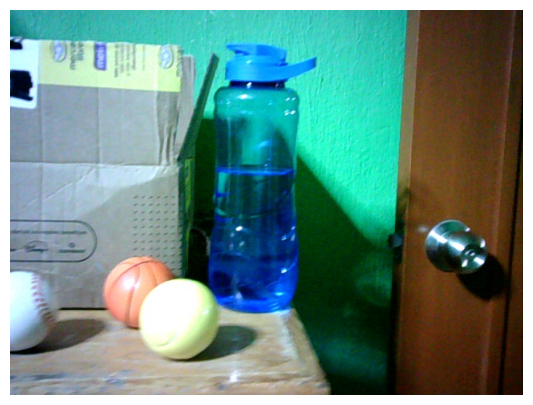

In [125]:
# Mostrar un par de imagenes de forma aleatoria
print(f"Tamaño de la secuencia: {len(monocular_vision.sequence)}")
index=np.random.randint(len(monocular_vision.sequence))
image_bgr=monocular_vision.sequence[index]
image_rgb=cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 5)) 
plt.imshow(image_rgb)
plt.axis('off')  
plt.show()

In [17]:
# Mostrar secuencia completa
monocular_vision.show_sequence(fps=15, replay=True)

# Conteo de objetos usando vision monocular

In [49]:
# Coordenadas del area candidata
def get_candidate_area_coords(coords, h, w, image_shape, pad_hw=(0,0)):
    # image_shape: (height,width)
    hi,wi=image_shape
    ph,pw=pad_hw
    # Coordenadas bounding box de referencia
    xrmin,yrmin,xrmax,yrmax=np.array(coords).astype(int)
    # Coordenadas del area candidata
    # Realizamos ajuste para que las coordenadas queden dentro de la imagen
    candidate_area_coords=[
        np.clip(xrmin - w - pw, 0, wi - 1), # xmin
        np.clip(yrmin - h - ph, 0, hi - 1), # ymin
        np.clip(xrmax + pw    , 0, wi - 1), # xmax
        np.clip(yrmax + h + ph, 0, hi - 1)  # ymax
    ]
    return candidate_area_coords

In [50]:
# Parche de una imagen
def get_patch(img_bgr, coords, pad_hw=(0,0)):
    # Dimensiones de la imagen
    hi,wi=img_bgr.shape[0:2]
    # Coordenadas bounding box
    xmin,ymin,xmax,ymax=np.array(coords).astype(int)
    ph,pw=pad_hw
    xmin=int(np.clip(xmin - pw, 0, wi - 1))
    ymin=int(np.clip(ymin - ph, 0, hi - 1))
    xmax=int(np.clip(xmax + pw, 0, wi - 1))
    ymax=int(np.clip(ymax + ph, 0, hi - 1))
    # Esquina superior izquierda
    p1=np.array([xmin, ymin]) 
    # Esquina inferior derecha
    p2=np.array([xmax, ymax]) 
    # Parche
    patch=img_bgr[ymin:ymax, xmin:xmax, :]
    return patch

In [51]:
# Devuelve verdadero si no es atipico, de lo contrario devuelve falso
# Toma en cuenta la distribucion normal
def nd_value_check(value, mean, std, n_std):
    return value >= mean - n_std * std and value <= mean + n_std * std

def filter_by_similarity(detections, similarity_factor):
    temp_detections=[]
    # Filtrado por similitud
    # No deben existir detecciones muy similares
    indexes=np.arange(len(detections)).tolist()
    while len(indexes) > 0:
        i=indexes.pop(0)
        if len(indexes) == 0:
            temp_detections.append(detections[i])
            break
        coords=detections[i]
        # Verificamos que no exista otra deteccion muy similar
        # Una deteccion contra todas las demas
        # Centro del bounding box 
        x,y=bounding_box_midpoints([coords])[0]
        # Centro de los bounding boxes
        us=bounding_box_midpoints(detections)[indexes]
        norms=np.linalg.norm(us - np.tile(np.array([x,y]), (us.shape[0], 1)), axis=1)
        index=int(np.argmin(norms))
        # Ancho y alto del bounding box 
        w,h=coords[2] - coords[0],coords[3] - coords[1]
        # El umbral depende de las dimensiones del bounding box 
        d_threshold=np.minimum(w,h) * similarity_factor
        # Validaciones por distancia
        if norms[index] < d_threshold:
            # Nos quedamos con una deteccion de las dos (ya que son muy similares)
            # ¿Cual es mejor elegir?
            temp_detections.append(detections[i])
            indexes.pop(index)
        else:
            # La deteccion esta lo suficientemente lejos de las otras, por tanto, la agregamos
            temp_detections.append(detections[i])
    return temp_detections
    
def filter_correspondences(detections, output_threshold, input_threshold, image_shape, n_std, proportions_hw, similarity_factor, poblation):
    hi,wi=image_shape

    # Filtrado por zona
    temp_detections=[]
    for i,coords in enumerate(detections):
        # Centro del bounding box 
        x,y=bounding_box_midpoints([coords])[0]
        if x > output_threshold:
            # Nos deshacemos de aquellas detecciones que ya han salido para no tomarlas en cuenta de nuevo
            if x > output_threshold and x <= input_threshold:
                # Nos quedamos con aquellas que estan en la zona de tracking
                temp_detections.append(detections[i])

    if len(temp_detections) > 0:
        # Filtrado por tamaño 
        # Todas las detecciones no deben exceder una tamaño de bounding box
        aux=[]
        ph,pw=proportions_hw
        for i,coords in enumerate(temp_detections):
            # Ancho y alto del bounding box en la imagen 1 y 2
            w,h=coords[2] - coords[0],coords[3] - coords[1]
            if h <= hi * ph and w <= wi * pw:
                aux.append(temp_detections[i])
        temp_detections=aux.copy()
    
    if len(temp_detections) > 0:
        # Filtrado por tamaño
        # Todas las detecciones deberian tener un tamaño de bounding box similar
        if len(poblation) > 0:
            aux=[]
            w_list=[]
            h_list=[]
            for coords in poblation:
                # Ancho y alto del bounding box 
                w,h=coords[2] - coords[0],coords[3] - coords[1]
                w_list.append(w)
                h_list.append(h)
            w_mean=np.mean(w_list)
            w_std=np.std(w_list)
            h_mean=np.mean(h_list)
            h_std=np.std(h_list)
            for i,coords in enumerate(temp_detections):
                # Ancho y alto del bounding box 
                w,h=coords[2] - coords[0],coords[3] - coords[1]
                # Mantenemos si el bounding box es como los demas bounding boxes 
                if nd_value_check(w, w_mean, w_std, n_std) and nd_value_check(h, h_mean, h_std, n_std):
                    aux.append(temp_detections[i])
            temp_detections=aux.copy()
      
    if len(temp_detections) > 0:
        # Filtrado por similitud
        # No deben existir detecciones muy similares
        temp_detections=filter_by_similarity(temp_detections, similarity_factor)

    return temp_detections

In [52]:
"""
Funcion de costo: 
    sum(abs(new_patch - old_patch))

Al final se tiene una funcion escalar de dos variables (x,y)

Podria agregarse a la funcion de costo una penalizacion dada la distancia que existe entre old_patch y new_patch
"""
# Trabaja con patches a color
def make_new_tracking(old_img_bgr, new_img_bgr, old_coords_list, space_hw, stride_hw, pad_hw):
    new_coords_list=[]
    h,w=space_hw
    sh,sw=stride_hw
    ph,pw=pad_hw
    for i, old_coords in enumerate(old_coords_list):
        # Coordenadas y dimensiones del bounding box de referencia (ancho y alto)
        xrmin, yrmin, xrmax, yrmax = np.array(old_coords).astype(int) 
        wr = xrmax - xrmin
        hr = yrmax - yrmin
        # Coordenadas del bounding box candidato 
        candidate_area_coords = get_candidate_area_coords(old_coords, h, w, image_shape=old_img_bgr.shape[0:2], pad_hw=pad_hw)
        xcmin, ycmin, xcmax, ycmax = candidate_area_coords
        # Kernel e imagen a utilizar (manteniendo los 3 canales de color normalizados)
        kernel = get_patch(old_img_bgr, old_coords, pad_hw) / 255.0
        img = get_patch(new_img_bgr, candidate_area_coords) / 255.0
        kernel_shape = kernel.shape  # Ahora es (Alto, Ancho, Canales)
        img_shape = img.shape
        # Tensores PyTorch: Reordenar de (Alto, Ancho, Canales) a (Canales, Alto, Ancho)
        kernel_tensor = torch.tensor(kernel, dtype=torch.float32).permute(2, 0, 1)
        img_tensor = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)
        # Adaptar las dimensiones a 4D (Batch, Channels, Height, Width) agregando el Batch
        kernel_tensor = kernel_tensor.unsqueeze(0)
        img_tensor = img_tensor.unsqueeze(0)
        # Extraer los parches usando unfold (solo se pasan las dimensiones espaciales Alto y Ancho al kernel_size)
        # Resultado: (Batch, Canales * kh * kw, Número_de_bloques)
        patches_tensor = torch.nn.functional.unfold(img_tensor, kernel_size=kernel_shape[:2], stride=stride_hw, padding=0)
        # Preparar el kernel y los parches para la resta
        # Aplanamos el kernel a un vector de N elementos y lo reestructuramos a (1, N, 1)
        # Usamos .reshape() en lugar de .view() porque .permute() hace que el tensor no sea contiguo
        kernel_plain_tensor = kernel_tensor.reshape(1, int(np.prod(kernel_shape)), 1)
        # Suma de las diferencias absolutas
        sum_abs_diff_tensor = torch.abs(patches_tensor - kernel_plain_tensor).sum(dim=1, keepdim=True) 
        # Calcular las dimensiones de la matriz de salida
        h_out = (img_shape[0] - kernel_shape[0]) // stride_hw[0] + 1
        w_out = (img_shape[1] - kernel_shape[1]) // stride_hw[1] + 1
        # Reestructurar el resultado de vuelta a una matriz 2D (usando reshape por seguridad)
        cost_tensor = sum_abs_diff_tensor.reshape(1, 1, h_out, w_out)
        cost_tensor = cost_tensor.squeeze(0).squeeze(0)
        # Transformar a Numpy
        cost = cost_tensor.numpy()
        # Elegimos la posicion con el menor costo
        best_cost_p = np.array(np.unravel_index(np.argmin(cost), cost.shape))
        # Nueva posicion
        new_coords = [
            xcmin + best_cost_p[1] * sw + pw,      # xmin
            ycmin + best_cost_p[0] * sh + ph,      # ymin
            xcmin + best_cost_p[1] * sw + pw + wr, # xmax
            ycmin + best_cost_p[0] * sh + ph + hr  # ymax
        ]
        new_coords_list.append(new_coords)
    return new_coords_list

In [53]:
def adjust_and_add_tracking(new_tracking, detections, similarity_factor):
    temp_new_tracking=[]
    temp_detections=detections.copy()
    if len(temp_detections) > 0:
        # Ajustar tracking en caso de ser necesario
        for i in range(len(new_tracking)):
            if len(temp_detections) > 0:
                # Coordenadas del bounding box
                coordst=new_tracking[i]
                # Ancho y alto del bounding box
                wt,ht=coordst[2] - coordst[0],coordst[3] - coordst[1]
                # Centro del bounding box
                ut=bounding_box_midpoints([coordst])[0]
                # Centro de los bounding boxes de las detecciones
                uds=bounding_box_midpoints(temp_detections)
                norms=np.linalg.norm(uds - np.tile(ut, (uds.shape[0], 1)), axis=1)
                index=int(np.argmin(norms))
                # El umbral depende de las dimensiones del bounding box de tracking
                d_threshold=np.minimum(wt, ht) * similarity_factor
                # Validaciones por distancia
                if norms[index] < d_threshold:
                    # Encontramos una deteccion candidata
                    # Nos quedamos con la deteccion
                    temp_new_tracking.append(temp_detections[index].copy())
                    temp_detections.pop(index)
                else:
                    # Mantenemos el tracking
                    temp_new_tracking.append(new_tracking[i].copy())
            else:
                # Mantenemos el tracking
                temp_new_tracking.append(new_tracking[i].copy())  
        # Las detecciones restantes las agregamos al tracking
        temp_new_tracking.extend(temp_detections)
        return temp_new_tracking
    else:
        return new_tracking.copy()

In [54]:
def check_tracking(new_img_bgr, new_tracking, output_threshold):
    temp_new_tracking=[]
    out=0
    tracking_patches=[]    
    tracking_out=[]
    for i in range(len(new_tracking)):
        coords=new_tracking[i]
        # Centro del bounding box
        x,y=bounding_box_midpoints([coords])[0]
        if x <= output_threshold:
            # Nos deshacemos de los que se encuentran en la zona de salida
            out+=1
            tracking_patches.append(get_patch(new_img_bgr, new_tracking[i]))
            tracking_out.append(new_tracking[i])
            print("Objeto contado !!!") 
        else:
            temp_new_tracking.append(new_tracking[i].copy())    
    return temp_new_tracking,out,tracking_patches,tracking_out

In [ ]:
def show_sequence_detections(
    monocular_vision, 
    fps, 
    output_threshold, 
    input_threshold, 
    space_hw, 
    stride_hw, 
    pad_hw,
    n_std,
    proportions_hw,
    similarity_factor,
    poblation_limit
):
    # Parametros de calibracion
    K,q=monocular_vision.get_calibration_parameters()
    # Dimensiones de las imagenes (h,w)
    image_shape=monocular_vision.sequence[0].shape[0:2]
    hi,wi=image_shape
    # Delay en milisegundos
    delay = int(1000 / fps) 
    start=0
    end=len(monocular_vision.sequence)

    old_img_bgr=None
    new_img_bgr=None
    old_tracking=[]
    new_tracking=[]
    count=0
    patches=[]
    poblation=[]
    images=[]
    for t in range(start,end):
        distorted_image_bgr=monocular_vision.sequence[t]
        # Imagen sin distorsion
        image_bgr=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr, K, q)

        # Guardamos la nueva y antigua imagen de cada camara
        if t == 0:
            old_img_bgr=None
            new_img_bgr=image_bgr.copy()
        else:
            old_img_bgr=new_img_bgr.copy()
            new_img_bgr=image_bgr.copy()

        # Coordenadas de los bounding boxes
        detections=object_detection.detect_objects(image_bgr)

        # Nos quedamos solo con correspondencias que estan en zona de tracking
        detections=filter_correspondences(
            detections, 
            output_threshold, 
            input_threshold,
            image_shape,
            n_std,
            proportions_hw,
            similarity_factor,
            poblation
        )

        # Las asignamos para hacerles tracking a las detecciones
        if len(detections) > 0 and len(old_tracking) == 0:
            old_tracking=detections
        
        # Hacemos tracking
        if old_img_bgr is not None and new_img_bgr is not None:
            # Calculamos una nueva posicion para el tracking
            new_tracking=make_new_tracking(
                old_img_bgr, 
                new_img_bgr, 
                old_tracking, 
                space_hw,
                stride_hw, 
                pad_hw
            )

            # Ajustamos correspondencias a las que se les hace tracking y agregamos correspondencias nuevas al tracking
            new_tracking=adjust_and_add_tracking(
                new_tracking, 
                detections,
                similarity_factor
            )

            # Filtramos para no tener mas de un tracking similar
            new_tracking=filter_by_similarity(new_tracking, similarity_factor)

            # Verificamos el tracking
            new_tracking,out,tracking_patches,tracking_out=check_tracking(
                new_img_bgr, 
                new_tracking, 
                output_threshold
            )

            # Conteo
            count+=out
            patches.extend(tracking_patches)
            poblation.extend(tracking_out)
            while len(poblation) > poblation_limit:
                poblation.pop(0)
            
            # Actualizar
            old_tracking=new_tracking   
            
        # Dibujo de las correspondencias
        for coords in new_tracking:
            # Centro del bounding box
            u=bounding_box_midpoints([coords])[0]
            # Dibujar bounding box
            image_bgr=object_detection.draw_bounding_boxes(image_bgr, [coords])
            # Dibujar punto
            color=np.random.randint(0,255,3).tolist()
            image_bgr=cv2.circle(image_bgr, u.astype(int), radius=10, color=color, thickness=-1)

        image_bgr=cv2.putText(
            image_bgr, 
            f'{t}/{end - 1}', 
            (10, 30), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            1, 
            (0, 0, 255), 
            2, 
            cv2.LINE_AA
        )
        images.append(image_bgr)
        cv2.imshow(f"Video (presionar 'q' para salir)", image_bgr)    
        if cv2.waitKey(delay) & 0xFF == ord('q'):
            break
    cv2.destroyAllWindows()
    return count,patches,images

In [56]:
object_detection=ObjectDetection()

In [ ]:
# Dimensiones de las imagenes (h,w)
image_shape=monocular_vision.sequence[0].shape[0:2]
hi,wi=image_shape

count,patches,images=show_sequence_detections(
    monocular_vision, 
    fps=30, 
    output_threshold=wi * 0.5,     # Zona de salida
    input_threshold=wi - wi * 0.2, # Zona de entrada
    space_hw=(50,50),              # Espacio en alto y ancho sobre el bounding box de referencia para crear un bounding box mas grande sobre el, el cual se utiliza para hacer tracking
    stride_hw=(5,5),               # Funcionamiento similar al de las convoluciones, el cual se utiliza para hacer tracking
    pad_hw=(10,10),                # Funcionamiento similar al de las convoluciones, el cual se utiliza para hacer tracking
    n_std=3,                       # Numero de desviaciones estandar a considerar para filtrar por tamaño de bounding box
    proportions_hw=(0.5,0.5),      # Proporciones de alto y ancho de la imagen que no deben superar los bounding boxes
    similarity_factor=0.5,         # Factor de distancia que permite identificar bounding boxes similares
    poblation_limit=100,           # Tamaño de la memoria para guardar objetos una vez sean contados 
)

Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!
Objeto contado !!!


Count: 12


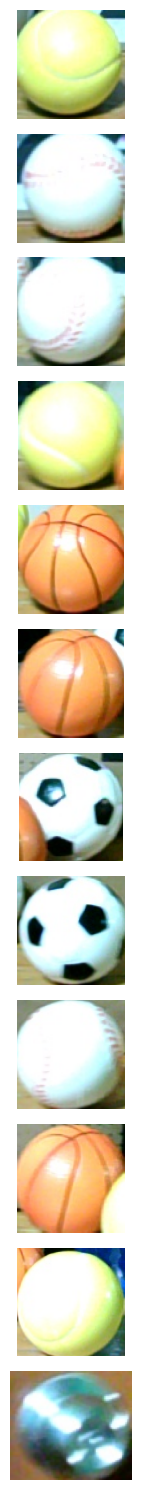

In [127]:
print(f"Count: {count}")
fig,axes=plt.subplots(len(patches), 1, figsize=(3, 15))
for i in range(len(patches)):
    axes[i].imshow(cv2.cvtColor(patches[i], cv2.COLOR_BGR2RGB))
    axes[i].axis('off')  
plt.tight_layout()
# Guardar resultados
sequence_name="sequence_08"
plt.savefig(f"{monocular_vision.path_sequences}/{sequence_name}/results-{monocular_vision.dual_camera.side}.png", dpi=300, bbox_inches="tight")
plt.show()

In [128]:
# Dimensiones de la imagen
h, w, d = images[0].shape
frame_size = (w, h)
# Configurar el VideoWriter
# Nombre del archivo de salida, códec FOURCC, FPS y tamaño
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
fps = 5.0
out = cv2.VideoWriter(f"{monocular_vision.path_sequences}/{sequence_name}/results-{monocular_vision.dual_camera.side}.mp4", fourcc, fps, frame_size)
# Recorrer la secuencia de imágenes y escribirlas en el video
for image in images:
    out.write(image)
# Liberar el objeto VideoWriter
out.release()
print("¡Video creado con éxito!")

¡Video creado con éxito!
